<a href="https://colab.research.google.com/github/mybenkhadda/WildSpeech/blob/main/WildSpeech_GPU/notebooks/WILDSPEECH_V4_MULTIMODAL_MASTER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WildSpeech V4 — Speech–Text–Acoustic Multimodal Intelligence (Google Colab)

This notebook drives `wildspeech.v4.pipeline.V4Pipeline` from the WildSpeech repository. Nothing in it re-implements the pipeline: every cell calls the package.

**What it does:** mounts Drive, clones WildSpeech (`main`, or an optional pinned commit), checks that the checkout is complete (every imported `wildspeech` module present, then the training modules import), installs it in editable mode, imports the completed external ASR export (`all_models_predictions.parquet`), validates audio/text/metadata joins, reuses or extracts acoustic features, builds recognized-text / disagreement / (measured) phonetic / acoustic student representations, evaluates M0–M8 on identical student-disjoint folds with ablations, negative controls and robustness schemes, tests H1–H10, produces figures, selects the champion from validated out-of-fold comparisons, refits it on all labelled students and writes a validated submission — all under `CONFIG['output_root']` on Drive.

> Commit `17222a0` (the earlier pin) is missing `src/wildspeech/models/` (excluded by an unanchored `models/` rule in `.gitignore`) and fails with `ModuleNotFoundError: No module named 'wildspeech.models'`. Do not pin it; the repaired `main` contains the package and cell 3 refuses incomplete checkouts.

**Before the first run**
1. Fill `V4_OVERRIDES['asr_import']['permission_review']` (cell 1). Without a completed review every ASR-derived family is `NOT_EXECUTED` (the tabular and acoustic experiments still run). The ASR predictions are imported with provenance `external_colab_asr`; they are never relabelled as local P24 output.
2. Run with `run_mode='PREPARE'` first and read `asr_import/asr_schema_report.json`. If a role (model / filename / transcript / phones ...) was not detected, set `V4_OVERRIDES['asr_import']['column_map']`.
3. Optional: upload a copy of a compatible local `cache/features` folder to Drive and list it in `V4_OVERRIDES['acoustic']['search_dirs']`; only fingerprint-compatible families are reused.

**Modes** (`CONFIG['run_mode']`): `PREPARE` → `FEATURES` → `EXPERIMENTS` → `SUBMISSION`, or `FULL` (all), or `SMOKE` (subsample, 1 repeat, no submission). Every step resumes from the artefacts already on Drive.

No empirical claim exists until these cells have been executed; the report is built from run artefacts only.

In [9]:
# 1. Configuration
CONFIG = {
    'repo': 'mybenkhadda/WildSpeech',
    'ref': 'main',                         # repaired revision (contains src/wildspeech/models/)
    'pinned_commit': None,                 # optional exact SHA for a reproducible rerun (cell 3 prints the resolved SHA)
    'project_subdir': 'WildSpeech_GPU',

    'data_root': '/content/drive/MyDrive/WildSpeech',
    'asr_root': '/content/drive/MyDrive/WildSpeech/WildSpeech_ASR_Exports',
    'asr_filename': 'all_models_predictions.parquet',
    'asr_drive_file_id': '12SzHSmkNbeoS_mO1L80uEd6A2k4jH-8V',   # used ONLY if the mounted file is missing

    'output_root': '/content/drive/MyDrive/WildSpeech/WildSpeech_V4',
    'local_work_root': '/content/wildspeech_v4',

    'run_mode': 'FULL',                    # FULL | PREPARE | FEATURES | EXPERIMENTS | SUBMISSION | SMOKE
    'max_clips': None,
    'splits': ['train', 'test'],

    'reuse_existing_features': True,
    'compute_missing_acoustic_features': True,
    'rerun_asr': False,                    # V4 imports the completed export; local ASR is not re-run
    'train_models': True,
    'generate_submission': True,

    'cv_folds': 5,
    'cv_repeats': 3,
    'seed': 2026,

    'use_gpu': True,
    'resume': True,
    'save_checkpoints': True,
}

# V4 settings (merged over configs/v4.yaml). Fill the permission review before importing ASR predictions.
V4_OVERRIDES = {
    'asr_import': {
        'permission_review': {
            'reviewed': False,           # True only after reviewing licences / competition rules of every exported model
            'reviewer': '',
            'date': '',                  # YYYY-MM-DD
            'statement': '',
            'models': [],                # [] = all exported models; otherwise only these model ids
        },
        'column_map': {},                # e.g. {'model_id': 'model', 'filename': 'audio_name', 'transcript': 'text'}
        'wide_model_columns': {},        # wide exports: {model_id: transcript_column}
    },
    'acoustic': {'search_dirs': []},     # e.g. ['/content/drive/MyDrive/WildSpeech/local_cache/features']
    'hier_net': {'enabled': False},      # M8 (evaluated only if an M1-M7 row is a GENUINE_GAIN)
}
print('run_mode =', CONFIG['run_mode'])

run_mode = FULL


In [10]:
# 2. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
import os
for k in ('data_root', 'asr_root'):
    print(f'{k:10s}', CONFIG[k], '->', 'found' if os.path.isdir(CONFIG[k]) else 'MISSING')
print('ASR export:', os.path.exists(os.path.join(CONFIG['asr_root'], CONFIG['asr_filename'])))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data_root  /content/drive/MyDrive/WildSpeech -> found
asr_root   /content/drive/MyDrive/WildSpeech/WildSpeech_ASR_Exports -> found
ASR export: True


In [11]:
# 3. Clone WildSpeech (repaired revision) + fail-fast source completeness check
import pathlib, subprocess, sys

def sh(cmd):
    print('$', cmd)
    subprocess.run(cmd, shell=True, check=True)

REPO_DIR = pathlib.Path('/content/WildSpeech')
if not (REPO_DIR / '.git').exists():
    sh(f"git clone https://github.com/{CONFIG['repo']}.git {REPO_DIR}")
sh(f'git -C {REPO_DIR} fetch --all --tags --prune')
target = CONFIG.get('pinned_commit') or f"origin/{CONFIG['ref']}"
sh(f'git -C {REPO_DIR} checkout --detach {target}')
COMMIT = subprocess.check_output(['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD']).decode().strip()
CONFIG['resolved_commit'] = COMMIT
print('WildSpeech commit:', COMMIT)
if not CONFIG.get('pinned_commit'):
    print(f"NOTE: floating ref {CONFIG['ref']!r}. For a reproducible rerun set CONFIG['pinned_commit'] = '{COMMIT}'")
PROJECT = REPO_DIR / CONFIG['project_subdir']
assert (PROJECT / 'src' / 'wildspeech' / 'v4' / 'pipeline.py').exists(), 'this revision has no V4 code'

# Gate 1 (before installing anything): parse every module with ast and verify that every wildspeech module
# referenced by any import exists in this checkout. Stdlib only, nothing heavy is imported.
for _k in [k for k in sys.modules if k == 'wildspeech' or k.startswith('wildspeech.')]:
    del sys.modules[_k]                              # never validate a stale import from an earlier checkout
sys.path.insert(0, str(PROJECT / 'src'))
from wildspeech.v4.source_check import assert_complete
_rep = assert_complete(PROJECT / 'src')              # raises SourceIncompleteError listing every missing module
print(f"source complete: {_rep['n_files']} modules checked at {COMMIT[:12]}")

$ git -C /content/WildSpeech fetch --all --tags --prune
$ git -C /content/WildSpeech checkout --detach origin/main
WildSpeech commit: aae183bba1c456cd5d4b7b636b685d585f91536e
NOTE: floating ref 'main'. For a reproducible rerun set CONFIG['pinned_commit'] = 'aae183bba1c456cd5d4b7b636b685d585f91536e'
source complete: 202 modules checked at aae183bba1c4


In [12]:
# 4. Install the package (editable) and the missing Colab-compatible dependencies.
#    No ASR foundation checkpoint is installed or loaded: the export is re-read, never re-inferred.
sh(f'{sys.executable} -m pip install -q -e {PROJECT}')
missing = []
for mod, pkg in [('catboost', 'catboost'), ('lightgbm', 'lightgbm'), ('xgboost', 'xgboost'), ('pygam', 'pygam'),
                 ('soxr', 'soxr'), ('pywt', 'PyWavelets'), ('soundfile', 'soundfile'), ('shap', 'shap'),
                 ('gdown', 'gdown'), ('g2p_en', 'g2p_en'), ('nltk', 'nltk'), ('yaml', 'pyyaml'), ('pyarrow', 'pyarrow')]:
    try:
        __import__(mod)
    except ImportError:
        missing.append(pkg)
if missing:
    sh(f"{sys.executable} -m pip install -q {' '.join(missing)}")
import nltk
for res in ('cmudict', 'averaged_perceptron_tagger_eng', 'averaged_perceptron_tagger'):
    try:
        nltk.download(res, quiet=True)
    except Exception as e:
        print('nltk', res, e)
if str(PROJECT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT / 'src'))          # editable install without a kernel restart
import importlib
import wildspeech
print('wildspeech from', wildspeech.__file__)
assert pathlib.Path(wildspeech.__file__).resolve().is_relative_to((PROJECT / 'src').resolve()), \
    'wildspeech is imported from a different location than the checked-out revision'

# Gate 2 (before any training): the modules training depends on must actually import here,
# not fail deep inside the experiments with ModuleNotFoundError.
from wildspeech.v4.source_check import REQUIRED_MODULES, assert_complete
assert_complete(PROJECT / 'src')
for _m in REQUIRED_MODULES:
    importlib.import_module(_m)
print('required modules import OK:', ', '.join(REQUIRED_MODULES))

$ /usr/bin/python3 -m pip install -q -e /content/WildSpeech/WildSpeech_GPU
wildspeech from /content/WildSpeech/WildSpeech_GPU/src/wildspeech/__init__.py
required modules import OK: wildspeech.models.zoo, wildspeech.models.preprocessing, wildspeech.models.residual_fusion, wildspeech.models.compact_regression, wildspeech.models.fusion, wildspeech.models.neural, wildspeech.evaluation.nested_asr_cv, wildspeech.validation.runner, wildspeech.v2.validation_registry, wildspeech.v4.pipeline


In [13]:
# 5. Build the V4 pipeline (resolves Drive paths, builds the run context, writes reports/run_config.json)
import pandas as pd
from IPython.display import Image, Markdown, display
from wildspeech.v4.config import resolve_asr_file
from wildspeech.v4.pipeline import V4Pipeline

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pipe = V4Pipeline(CONFIG, project_root=PROJECT, v4_overrides=V4_OVERRIDES)
print('data dir :', pipe.ctx.paths.data_dir)
display(pd.Series({k: str(v) for k, v in pipe.ctx.paths.files.items()}, name='discovered files'))
asr_path, asr_info = resolve_asr_file(pipe.run_cfg, allow_download=False)
print('ASR export:', asr_info)
PLAN = pipe.plan()
print('steps for', CONFIG['run_mode'], '->', PLAN + ['report'])

01:09:02 | INFO    | context: profile=V4 device=cuda root=/content/WildSpeech/WildSpeech_GPU data=/content/drive/MyDrive/WildSpeech
01:09:02 | INFO    | context: profile=V4 device=cuda root=/content/WildSpeech/WildSpeech_GPU data=/content/drive/MyDrive/WildSpeech


data dir : /content/drive/MyDrive/WildSpeech


,discovered files
train_clips,/content/drive/MyDrive/WildSpeech/train_clip_m...
test_clips,/content/drive/MyDrive/WildSpeech/test_clip_me...
train_students,/content/drive/MyDrive/WildSpeech/train_studen...
test_students,/content/drive/MyDrive/WildSpeech/test_student...
labels,/content/drive/MyDrive/WildSpeech/train_labels...
submission_format,/content/drive/MyDrive/WildSpeech/submission_f...
train_audio,/content/drive/MyDrive/WildSpeech/train_audio.tar
test_audio,/content/drive/MyDrive/WildSpeech/test_audio.tar


ASR export: {'mounted_path': '/content/drive/MyDrive/WildSpeech/WildSpeech_ASR_Exports/all_models_predictions.parquet', 'mounted_exists': True, 'source': 'mounted_drive', 'file_id': '12SzHSmkNbeoS_mO1L80uEd6A2k4jH-8V'}
steps for FULL -> ['prepare', 'features', 'experiments', 'figures', 'submission', 'report']


In [14]:
# 6. PREPARE — audio manifests, external ASR import (schema inspection, canonical adapter), joins, integrity
if 'prepare' in PLAN:
    print(pipe._step('prepare', pipe.prepare))
st = pipe.store
schema = st.load_json('asr_import', 'asr_schema_report.json', {}) or {}
print('layout:', schema.get('layout'), '| roles:', schema.get('roles'), '| warnings:', schema.get('warnings'))
for sub, name in [('asr_import', 'asr_coverage.csv'), ('asr_import', 'import_gate.csv'), ('manifests', 'join_audit.csv')]:
    t = st.load_table(sub, name)
    if t is not None:
        print(f'--- {sub}/{name}')
        display(t.head(40))
integ = st.load_json('manifests', 'data_integrity.json', {}) or {}
print({k: integ.get(k) for k in ('n_train_clips', 'n_test_clips', 'n_train_students', 'n_test_students', 'n_fail', 'n_warn')})

01:09:02 | INFO    | ===== V4 prepare
01:09:02 | INFO    | ===== V4 prepare
01:09:02 | INFO    | data: train 541 students / 14704 clips, test 361 / 9814, tasks=['blending', 'deletion', 'sentence_repetition'], thetas=['blending_theta', 'deletion_theta', 'sentence_repetition_theta']
01:09:02 | INFO    | data: train 541 students / 14704 clips, test 361 / 9814, tasks=['blending', 'deletion', 'sentence_repetition'], thetas=['blending_theta', 'deletion_theta', 'sentence_repetition_theta']
01:09:08 | INFO    | ASR import: 24518 source rows, layout=long, models=['facebook_wav2vec2_base_960h']
01:09:08 | INFO    | ASR import: 24518 source rows, layout=long, models=['facebook_wav2vec2_base_960h']


{'n_models': 1, 'usable_models': [], 'integrity_fail': 0}
layout: long | roles: {'model_id': 'model_id', 'model_version': 'model_revision', 'clip_id': 'clip_id', 'filename': 'audio_name', 'basename': 'basename', 'member': 'member', 'split': 'split_hint', 'source': 'source', 'transcript': 'text', 'status': 'status', 'audio_seconds': 'duration_s'} | warnings: []
--- asr_import/asr_coverage.csv


,model_key,model_id,split,n_metadata_clips,n_matched_rows,n_usable,n_failed,n_nonempty_transcript,n_empty_transcript,n_phone_strings,n_with_confidence,n_unmatched_rows,n_duplicates_discarded,n_missing_predictions,usable_frac,students_covered_frac,decode_seconds_mean
0,facebook_wav2vec2_base_960h,facebook/wav2vec2-base-960h,train,14704,14704,14704,0,14305,399,0,0,0,0,0,1.0,1.0,NaN
1,facebook_wav2vec2_base_960h,facebook/wav2vec2-base-960h,test,9814,9814,9814,0,9534,280,0,0,0,0,0,1.0,1.0,NaN


--- asr_import/import_gate.csv


,model_key,check,status,detail
0,facebook_wav2vec2_base_960h,permission_review,FAIL,v4.asr_import.permission_review.reviewed is fa...
1,facebook_wav2vec2_base_960h,provenance_external,PASS,sha256=ec9eea60a94823bc
2,facebook_wav2vec2_base_960h,one_prediction_per_clip,PASS,"0 duplicate (split, clip) rows after resolution"
3,facebook_wav2vec2_base_960h,coverage_train,PASS,usable 14704/14704 = 1.000 (min 0.5); failures=0
4,facebook_wav2vec2_base_960h,coverage_test,PASS,usable 9814/9814 = 1.000 (min 0.5); failures=0
5,facebook_wav2vec2_base_960h,nonempty_output,PASS,"23839 non-empty transcripts, 0 phone strings"


--- manifests/join_audit.csv


,check,status,value,detail,model_key
0,external manifest clip_id unique,PASS,0.0,duplicate clip_id rows in the external audio m...,NaN
1,ASR rows resolved through manifest clip_id,PASS,0.0,rows whose only identity was a clip_id,NaN
2,ASR split label agrees with metadata,PASS,0.0,split label differs from the split of the matc...,NaN
3,clip names present in both splits,PASS,0.0,ambiguous normalized names (left unmatched):,NaN
4,ASR rows matched to metadata,PASS,0.0,0/24518 unmatched; examples:,facebook_wav2vec2_base_960h
5,ASR audio duration agrees with metadata duration,PASS,0.0,|ASR audio_seconds - duration_sec| > 0.5 s + 5...,NaN
6,integrity: train clip count,PASS,14704.0,expected 14704,NaN
7,integrity: test clip count,PASS,9814.0,expected 9814,NaN
8,integrity: total clip count,PASS,24518.0,expected 24518,NaN
9,integrity: train students,PASS,541.0,expected ~541,NaN


{'n_train_clips': 14704, 'n_test_clips': 9814, 'n_train_students': 541, 'n_test_students': 361, 'n_fail': 0, 'n_warn': 0}


In [15]:
# 7. FEATURES — acoustic reuse / missing extraction, recognized text, disagreement, measured phonetics, providers
if 'features' in PLAN:
    print(pipe._step('features', pipe.features))
for sub, name in [('clip_features', 'acoustic_inventory.csv'), ('clip_features', 'acoustic_cache_reuse.csv'),
                  ('clip_features', 'phonetic_availability.csv')]:
    t = st.load_table(sub, name)
    if t is not None:
        print(f'--- {sub}/{name}')
        display(t)
cat = st.load_table('student_features', 'feature_catalog.parquet')
if cat is not None and len(cat):
    display(cat.groupby(['provider', 'family', 'modality', 'measurement']).size().rename('n_columns').reset_index())

01:09:12 | INFO    | ===== V4 features
01:09:12 | INFO    | ===== V4 features


{'text_models': [], 'phone_models': [], 'acoustic_columns': 23, 'providers': ['ACBL', 'ACDL', 'ACOU', 'ACSR', 'ASRCOR', 'REC']}
--- clip_features/acoustic_inventory.csv


,family,split,n_metadata_clips,n_cached,coverage,n_failed,fingerprint,expected_fingerprint,compatible,n_missing
0,temporal,train,14704,14704,1.0,0,3b03c349a51fc515,3b03c349a51fc515,True,0
1,temporal,test,9814,9814,1.0,0,3b03c349a51fc515,3b03c349a51fc515,True,0
2,spectral,train,14704,14704,1.0,0,b30082f3f058ef38,b30082f3f058ef38,True,0
3,spectral,test,9814,9814,1.0,0,b30082f3f058ef38,b30082f3f058ef38,True,0
4,mfcc,train,14704,14704,1.0,0,2cc8651de355368f,2cc8651de355368f,True,0
5,mfcc,test,9814,9814,1.0,0,2cc8651de355368f,2cc8651de355368f,True,0
6,pitch,train,14704,14704,1.0,0,c2b0427a1759b2c5,c2b0427a1759b2c5,True,0
7,pitch,test,9814,9814,1.0,0,c2b0427a1759b2c5,c2b0427a1759b2c5,True,0
8,quality,train,14704,14704,1.0,0,55859e2d169586fc,55859e2d169586fc,True,0
9,quality,test,9814,9814,1.0,0,55859e2d169586fc,55859e2d169586fc,True,0


--- clip_features/acoustic_cache_reuse.csv


,_no_results


--- clip_features/phonetic_availability.csv


,model_key,status,reason
0,*,UNAVAILABLE,no usable ASR model


,provider,family,modality,measurement,n_columns
0,ACBL,ACBL,acoustic,derived,118
1,ACDL,ACDL,acoustic,derived,118
2,ACOU,ACOU,acoustic,measured acoustics,312
3,ACSR,ACSR,acoustic,derived,118
4,ASRCOR,ASRCOR,text+acoustic,derived,49
5,REC,REC,recording_control,measured recording conditions,49


In [16]:
# 8. EXPERIMENTS — M0-M8, ablations, controls, robustness, fallback audit, H1-H10, importance, champion
if 'experiments' in PLAN:
    print(pipe._step('experiments', pipe.experiments))
cols = ['name', 'status', 'result_class', 'r2_mean', 'r2_sd', 'rmse', 'mae', 'delta_r2', 'delta_ci_low',
        'delta_ci_high', 'q', 'delta_r2_same_model', 'fallback_folds', 'n_added']
main = st.load_table('experiments', 'experiment_results.csv')
if main is not None:
    display(main[[c for c in cols if c in main.columns]])
fb = st.load_table('diagnostics', 'fallback_report.csv')
if fb is not None and 'is_fallback' in fb:
    print('--- rows that fell back to the baseline (NOT multimodal improvements)')
    display(fb[fb['is_fallback'] == True])
hyp = st.load_table('reports', 'hypotheses.csv')
if hyp is not None:
    display(hyp[[c for c in ('hypothesis', 'evidence', 'effect', 'ci_low', 'ci_high', 'experiment', 'result_class') if c in hyp]])
print('champion:', (st.load_json('model_registry', 'champion_spec.json', {}) or {}).get('name'))

01:09:23 | INFO    | ===== V4 experiments
01:09:23 | INFO    | ===== V4 experiments
01:09:38 | INFO    | V4 [1/13] repeated_kfold M0_RIDGE: status=ok r2=0.2211 dR2=0.003340603708358092
01:09:38 | INFO    | V4 [1/13] repeated_kfold M0_RIDGE: status=ok r2=0.2211 dR2=0.003340603708358092
01:09:38 | INFO    | V4 [2/13] repeated_kfold M0_GAM: status=ok r2=0.2180 dR2=None
01:09:38 | INFO    | V4 [2/13] repeated_kfold M0_GAM: status=ok r2=0.2180 dR2=None
01:10:21 | INFO    | V4 [3/13] repeated_kfold M0_CATBOOST: status=ok r2=0.1930 dR2=-0.004579966426929372
01:10:21 | INFO    | V4 [3/13] repeated_kfold M0_CATBOOST: status=ok r2=0.1930 dR2=-0.004579966426929372
01:10:30 | INFO    | V4 [4/13] repeated_kfold M0_LIGHTGBM: status=ok r2=0.1716 dR2=-0.02400076242334004
01:10:30 | INFO    | V4 [4/13] repeated_kfold M0_LIGHTGBM: status=ok r2=0.1716 dR2=-0.02400076242334004
01:10:30 | INFO    | V4 [5/13] repeated_kfold M0_SCREENING_RIDGE: status=ok r2=0.1995 dR2=-0.020307791901760575
01:10:30 | INFO   

{'n_rows': 58, 'champion': 'M0_GAM', 'champion_is_baseline': True}


,name,status,result_class,r2_mean,r2_sd,rmse,mae,delta_r2,delta_ci_low,delta_ci_high,q,delta_r2_same_model,fallback_folds,n_added
0,M0_RIDGE,ok,BASELINE_FALLBACK,0.221064,0.008177,9.819291,7.226594,0.003341,-0.015516,0.024242,0.810173,NaN,15,0.0
1,M0_GAM,ok,BASELINE,0.217953,0.007023,9.838920,7.279873,NaN,NaN,NaN,NaN,NaN,15,0.0
2,M0_CATBOOST,ok,BASELINE_FALLBACK,0.192967,0.008863,9.994809,7.417244,-0.004580,-0.044036,0.030705,0.810173,NaN,15,0.0
3,M0_LIGHTGBM,ok,BASELINE_FALLBACK,0.171562,0.008495,10.126504,7.519380,-0.024001,-0.068100,0.015579,0.521765,NaN,15,0.0
4,M0_SCREENING_RIDGE,ok,BASELINE_FALLBACK,0.199459,0.003620,9.954647,7.379582,-0.020308,-0.049681,0.009361,0.521765,NaN,15,0.0
5,M2_ACOU_RIDGE,ok,NO_DETECTABLE_EFFECT,0.195083,0.006190,9.981770,7.318920,-0.021207,-0.046318,0.006126,0.338835,-0.024547,0,20.0
6,M2_ACOU_CATBOOST,ok,NO_DETECTABLE_EFFECT,0.163994,0.007850,10.172675,7.564037,-0.033610,-0.072152,0.001646,0.338835,-0.029030,0,20.0
7,M5_RESID_ACOU,fallback_baseline,BASELINE_FALLBACK,0.217953,0.007023,9.838920,7.279873,0.000000,0.000000,0.000000,NaN,-0.003341,15,20.0
8,M5_RESID_ALL,fallback_baseline,BASELINE_FALLBACK,0.217953,0.007023,9.838920,7.279873,0.000000,0.000000,0.000000,NaN,-0.003341,15,20.0
9,M6_LATE_ALL,partial_fallback,BASELINE_FALLBACK,0.218723,0.007593,9.834056,7.236153,0.001300,-0.017615,0.022755,0.899550,-0.002041,9,20.0


--- rows that fell back to the baseline (NOT multimodal improvements)


,name,scheme,status,result_class,n_folds,fallback_folds,zero_effective_features_folds,zero_raw_features_folds,zero_variance_added_mean,zero_correction_variance_folds,alpha_zero_folds,zero_fusion_weight_folds,feature_delivery_failure,identical_to_baseline,fallback_reasons,is_fallback
0,M0_RIDGE,repeated_kfold,ok,BASELINE_FALLBACK,15,15,15,15,0.0,0,0,0,False,False,no added columns after reduction x15,True
1,M0_GAM,repeated_kfold,ok,BASELINE,15,15,15,15,0.0,0,0,0,False,NaN,no added columns after reduction x15,True
2,M0_CATBOOST,repeated_kfold,ok,BASELINE_FALLBACK,15,15,15,15,0.0,0,0,0,False,False,no added columns after reduction x15,True
3,M0_LIGHTGBM,repeated_kfold,ok,BASELINE_FALLBACK,15,15,15,15,0.0,0,0,0,False,False,no added columns after reduction x15,True
4,M0_SCREENING_RIDGE,repeated_kfold,ok,BASELINE_FALLBACK,15,15,15,15,0.0,0,0,0,False,False,no added columns after reduction x15,True
7,M5_RESID_ACOU,repeated_kfold,fallback_baseline,BASELINE_FALLBACK,15,15,0,0,4.0,15,15,0,False,True,residual shrinkage alpha=0 chosen by inner CV x15,True
8,M5_RESID_ALL,repeated_kfold,fallback_baseline,BASELINE_FALLBACK,15,15,0,0,4.0,15,15,0,False,True,residual shrinkage alpha=0 chosen by inner CV x15,True
9,M6_LATE_ALL,repeated_kfold,partial_fallback,BASELINE_FALLBACK,15,9,0,0,4.0,0,0,9,False,False,zero weight on every added-family member x9,True
11,M7_GATED_MOE,repeated_kfold,partial_fallback,BASELINE_FALLBACK,15,3,0,0,4.0,0,0,3,False,False,gated experts did not beat the stage-1 inner-O...,True
12,M7_DOMAIN_MOE,repeated_kfold,partial_fallback,BASELINE_FALLBACK,15,2,0,0,4.0,0,2,0,False,False,domain pooling lambda=0 or no domain expert x2,True


,hypothesis,evidence,effect,ci_low,ci_high,experiment,result_class
0,H1,unavailable,NaN,NaN,NaN,NaN,NaN
1,H2,none,-0.006545,-0.036251,0.026246,ABL_TASK_sentence_repetition,NO_DETECTABLE_EFFECT
2,H3,none,-0.010976,-0.033345,0.012432,H3_CORRECT_ONLY,NO_DETECTABLE_EFFECT
3,H4,unavailable,NaN,NaN,NaN,NaN,NaN
4,H5,unavailable,NaN,NaN,NaN,NaN,NaN
5,H6,unavailable,NaN,NaN,NaN,NaN,NaN
6,H7,not_interpretable,0.000000,0.000000,0.000000,M5_RESID_ALL,BASELINE_FALLBACK
7,H8,none,-0.002209,-0.288261,0.290531,NaN,NaN
8,H9,none,-0.012403,-0.057763,0.026468,NaN,NaN
9,H10,descriptive,2.000000,NaN,NaN,NaN,NaN


champion: M0_GAM


01:22:10 | INFO    | ===== V4 figures
01:22:10 | INFO    | ===== V4 figures
/content/WildSpeech/WildSpeech_GPU/src/wildspeech/v4/figures.py:183: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  m.groupby(["panel", "outcome_tercile"])["value"].describe().reset_index(),


{'n_figures': 20, 'n_failed': 1}


,figure,status,caption,n
0,01_asr_model_coverage,ok,"Usable (successful, matched, non-null) predict...",24518.0
1,02_audio_text_alignment,ok,Join coverage per split and task (audio manife...,24518.0
2,03_wer_cer_by_task,ok,NOT AVAILABLE: no recognized-text features,NaN
3,04_transcript_examples,ok,NOT AVAILABLE: no examples,NaN
4,05_phoneme_confusion,ok,NOT AVAILABLE: no measured phone predictions i...,NaN
5,06_screening_vs_linguistic,ok,NOT AVAILABLE: missing theta_mean / missing,NaN
6,07_speech_vs_outcome,ok,NOT AVAILABLE: missing missing / outcome_score,NaN
7,07b_acoustic_vs_outcome,ok,Descriptive association (not causal).,541.0
8,08_residual_correlations,ok,Descriptive association of student features (f...,541.0
9,09_task_conditioned_distributions,ok,NOT AVAILABLE: no text features,NaN


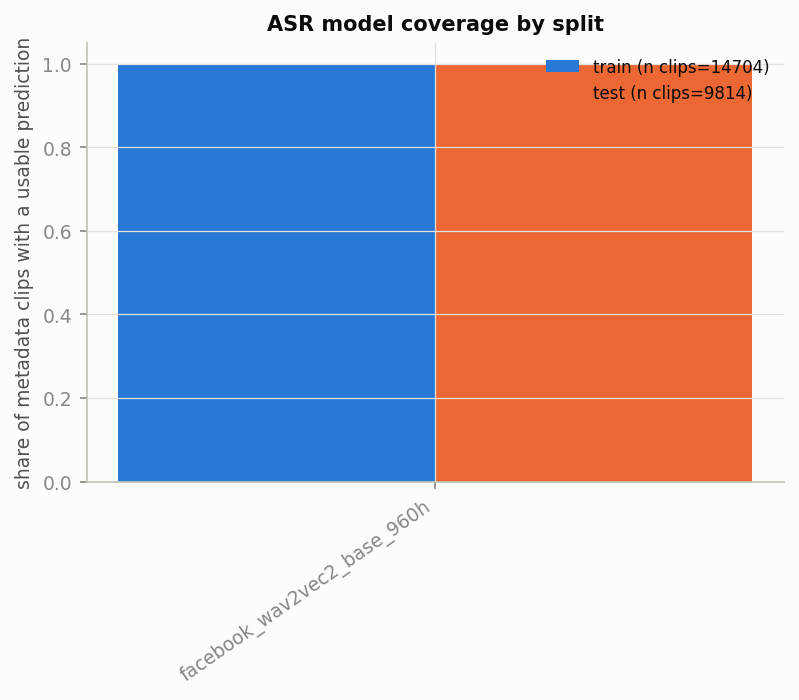

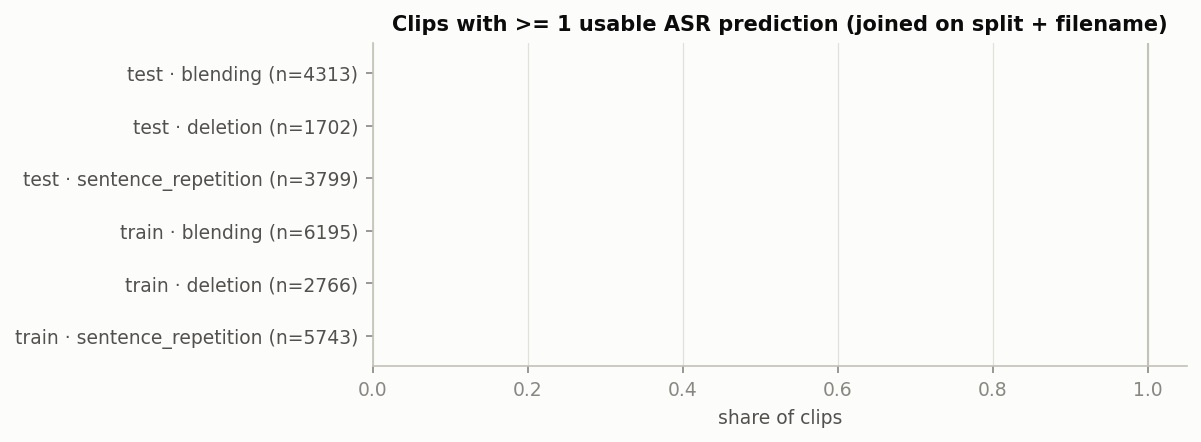

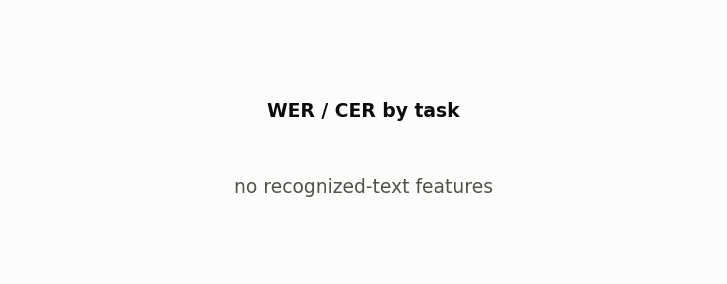

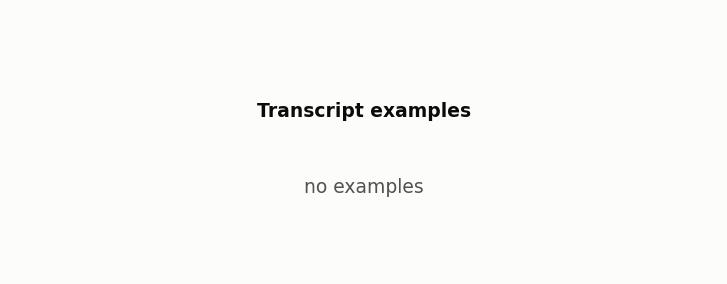

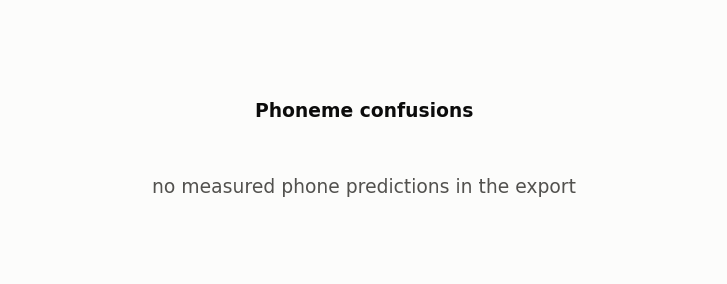

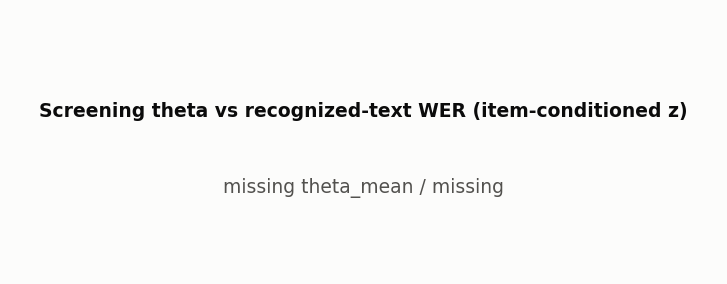

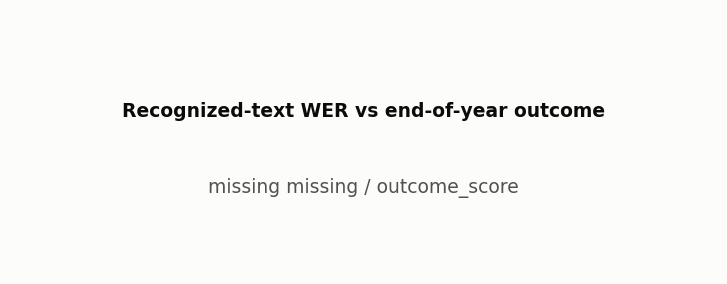

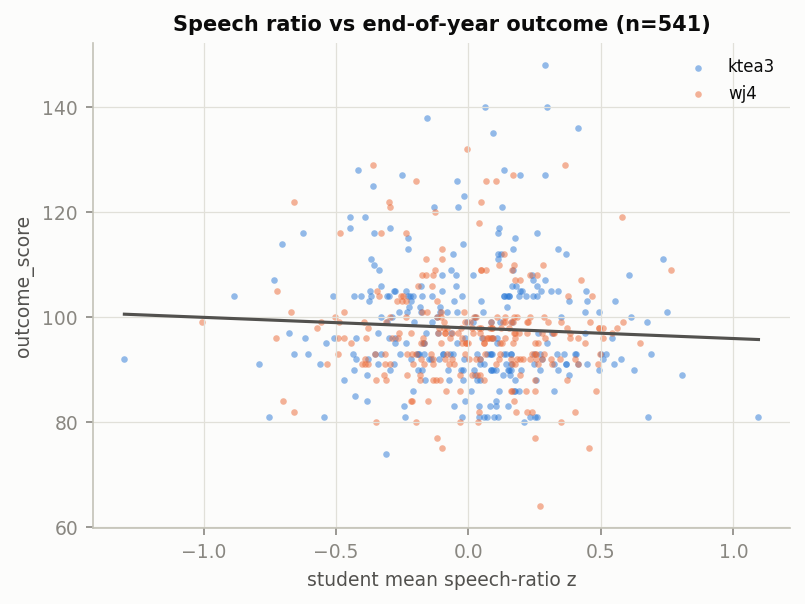

In [17]:
# 9. FIGURES — PNG + SVG + data tables under figures/
if 'figures' in PLAN:
    print(pipe._step('figures', pipe.figures))
idx = st.load_table('figures', 'figure_index.csv')
if idx is not None:
    display(idx[[c for c in ('figure', 'status', 'caption', 'n') if c in idx]])
    for p in idx.loc[idx['status'] == 'ok', 'png'].head(8):
        display(Image(filename=p))

In [18]:
# 10. SUBMISSION — champion refit on all labelled students, re-load from disk, validated submission.csv
if 'submission' in PLAN:
    print(pipe._step('submission', pipe.submission))
val = st.load_table('submission', 'submission_validation.csv')
if val is not None:
    display(val)
sub = st.load_table('submission', 'submission.csv')
if sub is not None:
    display(sub.describe())

01:22:18 | INFO    | ===== V4 submission
01:22:18 | INFO    | ===== V4 submission


{'file': '/content/drive/MyDrive/WildSpeech/WildSpeech_V4/submission/submission.csv', 'rows': 361, 'champion': 'M0_GAM', 'champion_is_baseline': True, 'champion_reason': 'no multimodal row is a validated GENUINE_GAIN with test coverage: the validated reference baseline is the champion (this is NOT a multimodal result)', 'pred_mean': 97.58281108886973, 'pred_sd': 5.100423962319433, 'n_clipped': 0, 'model_file': '/content/drive/MyDrive/WildSpeech/WildSpeech_V4/models/champion_fold_model.joblib', 'n_design_columns': 60, 'created': '2026-11-22T01:22:19'}


,check,status,detail
0,columns match format,PASS,"['subject_id', 'outcome_score'] vs ['subject_i..."
1,row count,PASS,361 vs 361
2,same ids,PASS,NaN
3,same order,PASS,NaN
4,unique ids,PASS,NaN
5,numeric target,PASS,0 non-numeric
6,finite target,PASS,NaN
7,non-constant predictions,PASS,NaN
8,no NaN predictions,PASS,0 NaN
9,no infinite predictions,PASS,0 inf


,outcome_score
count,361.000000
mean,97.582811
std,5.107503
min,85.213203
25%,93.657575
50%,97.310766
75%,101.532457
max,109.690855


In [19]:
# 11. REPORT + artefact inventory (everything is already on Drive under output_root)
report_path = pipe._step('report', pipe.report)
print('report:', report_path)
display(Markdown(open(report_path, encoding='utf-8').read()))
inv = st.load_table('reports', 'artifact_inventory.csv')
if inv is not None:
    display(inv)
display(pd.DataFrame(pipe.steps))

01:22:19 | INFO    | ===== V4 report
01:22:19 | INFO    | ===== V4 report


report: /content/drive/MyDrive/WildSpeech/WildSpeech_V4/reports/WILDSPEECH_V4_RESEARCH_REPORT.md


# WildSpeech V4 — Speech–Text–Acoustic Multimodal Intelligence
_Generated 2026-11-22 01:22:20 from run artefacts only. Repository ref: `mybenkhadda/WildSpeech@main`, run_mode `FULL`, 5-fold x 3 repeats, seed 2026._
> Every number below was produced by the executed notebook. Associations are not causal. Recognized-text error mixes the child's response with recognizer error and is not a verified pronunciation error. Fallback rows (status `fallback_baseline` / class `BASELINE_FALLBACK`) are not multimodal improvements.
## 1. Data integrity and joins
Train clips 14704, test clips 9814, train students 541, test students 361; 0 FAIL / 0 WARN checks.

| check | status | value | detail |
| --- | --- | --- | --- |
| train clip count | PASS | 14704.0000 | expected 14704 |
| test clip count | PASS | 9814.0000 | expected 9814 |
| total clip count | PASS | 24518.0000 | expected 24518 |
| train students | PASS | 541.0000 | expected ~541 |
| train normalized clip names unique (one-to-one key) | PASS | 0.0000 | collisions:  |
| train metadata filenames unique | PASS | 0.0000 |  |
| test normalized clip names unique (one-to-one key) | PASS | 0.0000 | collisions:  |
| test metadata filenames unique | PASS | 0.0000 |  |
| train/test students disjoint | PASS | 0.0000 | students in both splits |
| train/test clip owners disjoint | PASS | 0.0000 | clip subject_ids in both splits |
| labels only for train students | PASS | 0.0000 |  |
| every train student labelled | PASS | 0.0000 |  |
| train metadata clips present in audio manifest | PASS | 0.0000 | missing:  |
| train audio manifest has no unlisted audio | PASS | 0.0000 | unlisted:  |
| train audio manifest names unique within each manifest | PASS | 0.0000 | duplicate normalized names inside one manifest (first occurrence used) |
| test metadata clips present in audio manifest | PASS | 0.0000 | missing:  |
| test audio manifest has no unlisted audio | PASS | 0.0000 | unlisted:  |
| test audio manifest names unique within each manifest | PASS | 0.0000 | duplicate normalized names inside one manifest (first occurrence used) |
| one ASR prediction per model x clip after resolution | PASS | 0.0000 |  |
| no test student in train ASR rows | PASS | 0.0000 |  |
| school_id absent from test | PASS |  | train-only: grouping / robustness only |
| score_status absent from test | PASS |  | train-only: never a feature |

## 2. External ASR import (`external_colab_asr`)
Source `all_models_predictions.parquet` sha256 `ec9eea60a94823bc…`, layout `long`, 24518 source rows, models ['facebook_wav2vec2_base_960h']. Usable after the independent gate: []. Permission review: v4.asr_import.permission_review.reviewed is false.

| model_key | split | n_metadata_clips | n_usable | n_failed | n_unmatched_rows | n_duplicates_discarded | usable_frac | n_phone_strings |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| facebook_wav2vec2_base_960h | train | 14704 | 14704 | 0 | 0 | 0 | 1.0000 | 0 |
| facebook_wav2vec2_base_960h | test | 9814 | 9814 | 0 | 0 | 0 | 1.0000 | 0 |

Gate:

| model_key | check | status | detail |
| --- | --- | --- | --- |
| facebook_wav2vec2_base_960h | permission_review | FAIL | v4.asr_import.permission_review.reviewed is false (ASR families are NOT_EXECUTED until reviewed) |
| facebook_wav2vec2_base_960h | provenance_external | PASS | sha256=ec9eea60a94823bc |
| facebook_wav2vec2_base_960h | one_prediction_per_clip | PASS | 0 duplicate (split, clip) rows after resolution |
| facebook_wav2vec2_base_960h | coverage_train | PASS | usable 14704/14704 = 1.000 (min 0.5); failures=0 |
| facebook_wav2vec2_base_960h | coverage_test | PASS | usable 9814/9814 = 1.000 (min 0.5); failures=0 |
| facebook_wav2vec2_base_960h | nonempty_output | PASS | 23839 non-empty transcripts, 0 phone strings |

## 3. Phonetic availability
| model_key | status | reason |
| --- | --- | --- |
| * | UNAVAILABLE | no usable ASR model |

## 4. Feature families
| provider | family | modality | measurement | n_columns |
| --- | --- | --- | --- | --- |
| ACBL | ACBL | acoustic | derived | 118 |
| ACDL | ACDL | acoustic | derived | 118 |
| ACOU | ACOU | acoustic | measured acoustics | 312 |
| ACSR | ACSR | acoustic | derived | 118 |
| ASRCOR | ASRCOR | text+acoustic | derived | 49 |
| REC | REC | recording_control | measured recording conditions | 49 |

## 5. Baseline reproduction
| name | status | r2_mean | r2_sd | rmse | mae |
| --- | --- | --- | --- | --- | --- |
| M0_RIDGE | ok | 0.2211 | 0.0082 | 9.8193 | 7.2266 |
| M0_GAM | ok | 0.2180 | 0.0070 | 9.8389 | 7.2799 |
| M0_CATBOOST | ok | 0.1930 | 0.0089 | 9.9948 | 7.4172 |
| M0_LIGHTGBM | ok | 0.1716 | 0.0085 | 10.1265 | 7.5194 |
| M0_SCREENING_RIDGE | ok | 0.1995 | 0.0036 | 9.9546 | 7.3796 |

Historical reference (V1/V2 repeated-CV tabular GAM): R² ≈ 0.2153 — historical; comparable only after reproduction on the V4 folds. V4 reproduction on the V4 folds: R² = 0.2180.

## 6. Multimodal model ladder (primary scheme)
| name | status | result_class | r2_mean | r2_sd | rmse | mae | delta_r2 | delta_ci_low | delta_ci_high | q | delta_r2_same_model | fallback_folds | n_added |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| M2_ACOU_RIDGE | ok | NO_DETECTABLE_EFFECT | 0.1951 | 0.0062 | 9.9818 | 7.3189 | -0.0212 | -0.0463 | 0.0061 | 0.3388 | -0.0245 | 0 | 20.0000 |
| M2_ACOU_CATBOOST | ok | NO_DETECTABLE_EFFECT | 0.1640 | 0.0079 | 10.1727 | 7.5640 | -0.0336 | -0.0722 | 0.0016 | 0.3388 | -0.0290 | 0 | 20.0000 |
| M5_RESID_ACOU | fallback_baseline | BASELINE_FALLBACK | 0.2180 | 0.0070 | 9.8389 | 7.2799 | 0.0000 | 0.0000 | 0.0000 |  | -0.0033 | 15 | 20.0000 |
| M5_RESID_ALL | fallback_baseline | BASELINE_FALLBACK | 0.2180 | 0.0070 | 9.8389 | 7.2799 | 0.0000 | 0.0000 | 0.0000 |  | -0.0033 | 15 | 20.0000 |
| M6_LATE_ALL | partial_fallback | BASELINE_FALLBACK | 0.2187 | 0.0076 | 9.8341 | 7.2362 | 0.0013 | -0.0176 | 0.0228 | 0.8996 | -0.0020 | 9 | 20.0000 |
| M6_STACK_ALL | ok | NO_DETECTABLE_EFFECT | 0.2152 | 0.0042 | 9.8562 | 7.2566 | -0.0017 | -0.0089 | 0.0066 | 0.8078 | -0.0050 | 0 | 20.0000 |
| M7_GATED_MOE | partial_fallback | BASELINE_FALLBACK | 0.2181 | 0.0068 | 9.8381 | 7.2773 | 0.0002 | -0.0004 | 0.0009 | 0.7532 | -0.0031 | 3 | 20.0000 |
| M7_DOMAIN_MOE | partial_fallback | BASELINE_FALLBACK | 0.1981 | 0.0073 | 9.9629 | 7.3029 | -0.0176 | -0.0426 | 0.0091 | 0.3626 | -0.0210 | 2 | 20.0000 |

## 7. Fallback audit
| name | scheme | status | fallback_folds | n_folds | alpha_zero_folds | zero_effective_features_folds | zero_correction_variance_folds | zero_fusion_weight_folds | fallback_reasons |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| M0_RIDGE | repeated_kfold | ok | 15 | 15 | 0 | 15 | 0 | 0 | no added columns after reduction x15 |
| M0_GAM | repeated_kfold | ok | 15 | 15 | 0 | 15 | 0 | 0 | no added columns after reduction x15 |
| M0_CATBOOST | repeated_kfold | ok | 15 | 15 | 0 | 15 | 0 | 0 | no added columns after reduction x15 |
| M0_LIGHTGBM | repeated_kfold | ok | 15 | 15 | 0 | 15 | 0 | 0 | no added columns after reduction x15 |
| M0_SCREENING_RIDGE | repeated_kfold | ok | 15 | 15 | 0 | 15 | 0 | 0 | no added columns after reduction x15 |
| M5_RESID_ACOU | repeated_kfold | fallback_baseline | 15 | 15 | 15 | 0 | 15 | 0 | residual shrinkage alpha=0 chosen by inner CV x15 |
| M5_RESID_ALL | repeated_kfold | fallback_baseline | 15 | 15 | 15 | 0 | 15 | 0 | residual shrinkage alpha=0 chosen by inner CV x15 |
| M6_LATE_ALL | repeated_kfold | partial_fallback | 9 | 15 | 0 | 0 | 0 | 9 | zero weight on every added-family member x9 |
| M7_GATED_MOE | repeated_kfold | partial_fallback | 3 | 15 | 0 | 0 | 0 | 3 | gated experts did not beat the stage-1 inner-OOF MSE (all expert weights set to 0) x3 |
| M7_DOMAIN_MOE | repeated_kfold | partial_fallback | 2 | 15 | 2 | 0 | 0 | 0 | domain pooling lambda=0 or no domain expert x2 |
| H3_CORRECT_ONLY_RESID | repeated_kfold | fallback_baseline | 15 | 15 | 15 | 0 | 15 | 0 | residual shrinkage alpha=0 chosen by inner CV x15 |
| M5_RESID_ALL | school_kfold | fallback_baseline | 5 | 5 | 5 | 0 | 5 | 0 | residual shrinkage alpha=0 chosen by inner CV x5 |
| M7_GATED_MOE | school_kfold | partial_fallback | 1 | 5 | 0 | 0 | 0 | 1 | gated experts did not beat the stage-1 inner-OOF MSE (all expert weights set to 0) x1 |
| M5_RESID_ALL | loso | fallback_baseline | 14 | 14 | 14 | 0 | 14 | 0 | residual shrinkage alpha=0 chosen by inner CV x14 |
| M7_GATED_MOE | loso | partial_fallback | 3 | 14 | 0 | 0 | 0 | 3 | gated experts did not beat the stage-1 inner-OOF MSE (all expert weights set to 0) x3 |
| M5_RESID_ALL | sample_rate_transfer | fallback_baseline | 2 | 2 | 2 | 0 | 2 | 0 | residual shrinkage alpha=0 chosen by inner CV x2 |
| M5_RESID_ALL | instrument_transfer | fallback_baseline | 2 | 2 | 2 | 0 | 2 | 0 | residual shrinkage alpha=0 chosen by inner CV x2 |
| M5_RESID_ALL | sample_rate_equal_n | fallback_baseline | 20 | 20 | 20 | 0 | 20 | 0 | residual shrinkage alpha=0 chosen by inner CV x20 |
| M7_GATED_MOE | sample_rate_equal_n | partial_fallback | 8 | 20 | 0 | 0 | 0 | 8 | gated experts did not beat the stage-1 inner-OOF MSE (all expert weights set to 0) x8 |

## 8. Ablations and negative controls
| name | group | status | result_class | r2_mean | delta_r2 | delta_ci_low | delta_ci_high | q |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ABL_FAMILY_ACOU | family | ok | NO_DETECTABLE_EFFECT | 0.1951 | -0.0212 | -0.0463 | 0.0061 | 0.1129 |
| ABL_TASK_blending | task | ok | NO_DETECTABLE_EFFECT | 0.1978 | -0.0188 | -0.0426 | 0.0050 | 0.1823 |
| ABL_TASK_deletion | task | ok | NO_DETECTABLE_EFFECT | 0.1947 | -0.0225 | -0.0441 | 0.0004 | 0.1414 |
| ABL_TASK_sentence_repetition | task | ok | NO_DETECTABLE_EFFECT | 0.2095 | -0.0065 | -0.0363 | 0.0262 | 0.6814 |
| H3_CORRECT_ONLY | correct_only | ok | NO_DETECTABLE_EFFECT | 0.2067 | -0.0110 | -0.0333 | 0.0124 | 0.3473 |
| H3_CORRECT_ONLY_RESID | correct_only | fallback_baseline | BASELINE_FALLBACK | 0.2180 | 0.0000 | 0.0000 | 0.0000 |  |
| H9_INTERACT_RIDGE | interaction | ok | NO_DETECTABLE_EFFECT | 0.1951 | -0.0212 | -0.0463 | 0.0061 | 0.1129 |
| H9_INTERACT_CATBOOST | interaction | ok | NO_DETECTABLE_EFFECT | 0.1640 | -0.0336 | -0.0722 | 0.0016 | 0.1113 |
| H9_INTERACT_LIGHTGBM | interaction | ok | GENUINE_NEGATIVE | 0.1377 | -0.0572 | -0.0968 | -0.0205 | 0.0098 |
| ABL_BUDGET_pca_5 | budget | ok | NO_DETECTABLE_EFFECT | 0.2104 | -0.0064 | -0.0255 | 0.0161 | 0.5442 |
| ABL_BUDGET_pls_5 | budget | ok | GENUINE_NEGATIVE | 0.0030 | -0.1717 | -0.2554 | -0.0998 | 0.0000 |
| ABL_BUDGET_select_5 | budget | ok | NO_DETECTABLE_EFFECT | 0.2078 | -0.0072 | -0.0290 | 0.0152 | 0.5442 |
| ABL_BUDGET_pca_10 | budget | ok | NO_DETECTABLE_EFFECT | 0.2077 | -0.0090 | -0.0307 | 0.0162 | 0.5421 |
| ABL_BUDGET_pls_10 | budget | ok | GENUINE_NEGATIVE | -0.1311 | -0.2716 | -0.3823 | -0.1860 | 0.0000 |
| ABL_BUDGET_select_10 | budget | ok | NO_DETECTABLE_EFFECT | 0.1979 | -0.0154 | -0.0417 | 0.0086 | 0.3063 |
| ABL_BUDGET_pca_20 | budget | ok | NO_DETECTABLE_EFFECT | 0.1951 | -0.0212 | -0.0463 | 0.0061 | 0.1936 |
| ABL_BUDGET_pls_20 | budget | ok | GENUINE_NEGATIVE | -0.4641 | -0.5072 | -0.6734 | -0.3751 | 0.0000 |
| ABL_BUDGET_select_20 | budget | ok | NO_DETECTABLE_EFFECT | 0.1930 | -0.0192 | -0.0480 | 0.0069 | 0.2536 |
| ABL_BUDGET_pca_40 | budget | ok | GENUINE_NEGATIVE | 0.1732 | -0.0422 | -0.0701 | -0.0145 | 0.0070 |
| ABL_BUDGET_pls_40 | budget | ok | GENUINE_NEGATIVE | -0.8978 | -0.7963 | -1.0175 | -0.6083 | 0.0000 |
| ABL_BUDGET_select_40 | budget | ok | NO_DETECTABLE_EFFECT | 0.1870 | -0.0249 | -0.0549 | 0.0033 | 0.1876 |
| CTRL_SHUFFLED_OUTCOME | control | ok | GENUINE_NEGATIVE | -0.0110 | -0.2285 | -0.2821 | -0.1646 | 0.0000 |
| ROB_MISSING_ACOU | missing_modality | ok | NO_DETECTABLE_EFFECT | 0.2168 | -0.0021 | -0.0210 | 0.0190 | 0.8394 |
| CTRL_RECORDING_ONLY | control | ok | NO_DETECTABLE_EFFECT | 0.1993 | -0.0190 | -0.0402 | 0.0054 | 0.1020 |
| H6_ACOU_PLUS_REC | domain | ok | NO_DETECTABLE_EFFECT | 0.1949 | -0.0215 | -0.0452 | 0.0043 | 0.0895 |

## 9. Robustness (school / LOSO / instrument / sample rate)
| name | scheme | status | result_class | r2_mean | delta_r2 | delta_ci_low | delta_ci_high |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ABL_FAMILY_ACOU | school_kfold | ok | NO_DETECTABLE_EFFECT | 0.1455 | -0.0238 | -0.0548 | 0.0068 |
| M2_ACOU_RIDGE | school_kfold | ok | NO_DETECTABLE_EFFECT | 0.1455 | -0.0238 | -0.0548 | 0.0068 |
| M5_RESID_ALL | school_kfold | fallback_baseline | BASELINE_FALLBACK | 0.1693 | 0.0000 | 0.0000 | 0.0000 |
| M7_GATED_MOE | school_kfold | partial_fallback | BASELINE_FALLBACK | 0.1681 | -0.0012 | -0.0046 | 0.0018 |
| ABL_FAMILY_ACOU | loso | ok | GENUINE_NEGATIVE | 0.1501 | -0.0357 | -0.0664 | -0.0031 |
| M2_ACOU_RIDGE | loso | ok | GENUINE_NEGATIVE | 0.1501 | -0.0357 | -0.0664 | -0.0031 |
| M5_RESID_ALL | loso | fallback_baseline | BASELINE_FALLBACK | 0.1858 | 0.0000 | 0.0000 | 0.0000 |
| M7_GATED_MOE | loso | partial_fallback | BASELINE_FALLBACK | 0.1859 | 0.0001 | -0.0006 | 0.0009 |
| ABL_FAMILY_ACOU | sample_rate_transfer | ok | GENUINE_GAIN | -0.0209 | 0.1125 | 0.0252 | 0.2021 |
| M2_ACOU_RIDGE | sample_rate_transfer | ok | GENUINE_GAIN | -0.0209 | 0.1125 | 0.0252 | 0.2021 |
| M5_RESID_ALL | sample_rate_transfer | fallback_baseline | BASELINE_FALLBACK | -0.1334 | 0.0000 | 0.0000 | 0.0000 |
| M7_GATED_MOE | sample_rate_transfer | ok | NO_DETECTABLE_EFFECT | -0.1333 | 0.0001 | -0.0006 | 0.0007 |
| ABL_FAMILY_ACOU | instrument_transfer | ok | GENUINE_NEGATIVE | -0.0929 | -0.1945 | -0.2614 | -0.1367 |
| M2_ACOU_RIDGE | instrument_transfer | ok | GENUINE_NEGATIVE | -0.0929 | -0.1945 | -0.2614 | -0.1367 |
| M5_RESID_ALL | instrument_transfer | fallback_baseline | BASELINE_FALLBACK | 0.1016 | 0.0000 | 0.0000 | 0.0000 |
| M7_GATED_MOE | instrument_transfer | ok | NO_DETECTABLE_EFFECT | 0.1009 | -0.0008 | -0.0027 | 0.0008 |
| ABL_FAMILY_ACOU | sample_rate_equal_n | ok | GENUINE_GAIN | 0.0599 | 0.0451 | 0.0059 | 0.0875 |
| M2_ACOU_RIDGE | sample_rate_equal_n | ok | NO_DETECTABLE_EFFECT | 0.0599 | 0.0451 | 0.0059 | 0.0875 |
| M5_RESID_ALL | sample_rate_equal_n | fallback_baseline | BASELINE_FALLBACK | 0.0148 | 0.0000 | 0.0000 | 0.0000 |
| M7_GATED_MOE | sample_rate_equal_n | partial_fallback | BASELINE_FALLBACK | 0.0152 | 0.0003 | -0.0008 | 0.0016 |

## 10. Hypotheses H1–H10
| hypothesis | question | evidence | effect | ci_low | ci_high | n_students | experiment | result_class | method | limitations |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| H1 | Does ASR recognized-text deviation predict end-of-year reading after adjusting for screening? | unavailable |  |  |  | 541 | nan | nan | ΔR² of baseline + recognized-text families (early fusion; best M1 estimator) vs the reference baseline, paired bootstrap of repeat-averaged OOF predictions; same folds | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. |
| H2 | Which task (blending, deletion, sentence repetition) contributes the most independent signal? | none | -0.0065 | -0.0363 | 0.0262 | 541 | ABL_TASK_sentence_repetition | NO_DETECTABLE_EFFECT | one provider per task (that task's clips only), each added alone to the baseline | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. Tasks differ in clip counts and adaptive administration; contributions are not additive. |
| H3 | Do acoustic / recognized-text characteristics of officially CORRECT responses predict reading differences? | none | -0.0110 | -0.0333 | 0.0124 | 541 | H3_CORRECT_ONLY | NO_DETECTABLE_EFFECT | text + acoustic features aggregated over officially CORRECT clips only (item-conditioned z-scores, fold-fitted), added to the baseline | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. Correct-response subsets are smaller for low-ability students (selection). |
| H4 | Does disagreement between recognizers carry literacy information or mainly recording artefacts? | unavailable |  |  |  | 541 | nan | nan | ΔR² of the cross-recognizer disagreement family + sequential variance decomposition of clip disagreement (item -> recording -> correctness -> student) | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. Needs >= 2 usable recognizers; disagreement is never interpreted as pronunciation difficulty. |
| H5 | Do measured phonetic error patterns and their within-student stability predict future reading? | unavailable |  |  |  | 541 | nan | nan | measured phonetic errors (ASRPHN) | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. The export contains no measured phone predictions; G2P of word transcripts is not a phonetic measurement. |
| H6 | How much of the apparent speech signal is explained by sample rate / instrument / school? | unavailable |  |  |  | 541 | nan | nan | ΔR²(text + recording-conditions control) − ΔR²(recording only), paired; transfer across sample rate / instrument / school schemes; partial correlations with recording metadata | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. school_id is used only for grouping (train-only); confounding is assessed, not removed. |
| H7 | Can speech features explain screening-model residuals on unseen students? | not_interpretable | 0.0000 | 0.0000 | 0.0000 | 541 | M5_RESID_ALL | BASELINE_FALLBACK | nested residual correction: speech families fitted to inner-OOF baseline residuals, shrinkage alpha chosen by inner CV; ΔR² on unseen students | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. |
| H8 | Which students are systematically under/over-estimated by screening-only models, and does multimodal modelling improve them? | none | -0.0022 | -0.2883 | 0.2905 | 541 | nan | nan | students in the top / bottom quintile of the baseline OOF residual (under / over-estimated): MAE reduction of the champion / best multimodal model, student bootstrap | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. Quintiles of OOF residuals regress to the mean; reductions are paired on the same students. |
| H9 | Do nonlinear interactions (theta x difficulty x fluency x text errors) add signal beyond additive models? | none | -0.0124 | -0.0578 | 0.0265 | 541 | nan | nan | paired ΔR² of boosted trees vs ridge on identical inputs (baseline + speech families) | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. |
| H10 | Which feature families remain reliable across folds, schools and recording conditions? | descriptive | 2.0000 |  |  | 541 | nan | nan | per family: ΔR² sign consistency across repeated K-fold, school-grouped, LOSO, instrument and sample-rate transfer + selection stability (Jaccard) | Observational association on ~541 students; not causal. Recognized-text error mixes child responses with recognizer error on child speech. |

## 11. Interpretability
| family | importance_mean | importance_sd | n_folds | ci_low | ci_high | name |
| --- | --- | --- | --- | --- | --- | --- |
| ITEM | 0.0906 | 0.0300 | 5 | 0.0643 | 0.1169 | M6_STACK_ALL |
| BEHAVIOR | 0.0785 | 0.0251 | 5 | 0.0565 | 0.1005 | M6_STACK_ALL |
| SCREENING | 0.0164 | 0.0093 | 5 | 0.0082 | 0.0246 | M6_STACK_ALL |
| ACOU | -0.0044 | 0.0106 | 5 | -0.0136 | 0.0049 | M6_STACK_ALL |

## 12. Champion and submission
Champion `M0_GAM` — no multimodal row is a validated GENUINE_GAIN with test coverage: the validated reference baseline is the champion (this is NOT a multimodal result) (R² 0.2179527425043215, ΔR² 0.0).

Submission `/content/drive/MyDrive/WildSpeech/WildSpeech_V4/submission/submission.csv`: 361 rows, prediction mean 97.583, sd 5.100, 0 clipped to the training range.

| check | status | detail |
| --- | --- | --- |
| columns match format | PASS | ['subject_id', 'outcome_score'] vs ['subject_id', 'outcome_score'] |
| row count | PASS | 361 vs 361 |
| same ids | PASS | nan |
| same order | PASS | nan |
| unique ids | PASS | nan |
| numeric target | PASS | 0 non-numeric |
| finite target | PASS | nan |
| non-constant predictions | PASS | nan |
| no NaN predictions | PASS | 0 NaN |
| no infinite predictions | PASS | 0 inf |
| no missing test students | PASS | nan |
| no duplicate test students | PASS | nan |
| test design rows == test students (same order) | PASS | nan |
| no train student in the test design | PASS | nan |
| no train-only field in the design | PASS | nan |
| no target-derived column in the design | PASS | nan |
| re-loaded model reproduces in-memory predictions | PASS | max /diff/ = 0 |

## 13. Limitations
* ~541 independent students: incremental effects are small relative to their bootstrap uncertainty; multiplicity is controlled with BH-FDR within (scheme, group).
* ASR predictions were produced externally; their quality on child speech bounds every text feature.
* Phonetic hypotheses require measured phone strings; G2P of recognized words is not a substitute.
* school_id / score_status are train-only and never prediction inputs; school effects are assessed with school-grouped and leave-one-school-out validation only.
* Results are associations; no causal interpretation.


,path,bytes,modified,schema_version,fingerprint
0,ablations/ablation_results.csv,15049,2026-11-22T01:21:22,4.0.0,NaN
1,asr_import/asr_coverage.csv,483,2026-11-22T01:09:10,4.0.0,NaN
2,asr_import/asr_import_report.json,1796,2026-11-22T01:09:10,4.0.0,NaN
3,asr_import/asr_schema_report.json,4038,2026-11-22T01:09:08,4.0.0,NaN
4,asr_import/canonical_predictions.parquet,5258402,2026-11-22T01:09:10,4.0.0,ec9eea60a94823bc44266bce4efc0d85b74b30036981cc...
...,...,...,...,...,...
211,submission/submission.csv,11288,2026-11-22T01:22:19,4.0.0,NaN
212,submission/submission_meta.json,580,2026-11-22T01:22:19,4.0.0,NaN
213,submission/submission_validation.csv,653,2026-11-22T01:22:19,4.0.0,NaN
214,submission/test_predictions.csv,22595,2026-11-22T01:22:19,4.0.0,NaN


,step,status,seconds
0,prepare,ok,10.042848
1,features,ok,10.439148
2,hypotheses,ok,9.952815
3,importance,ok,36.970926
4,experiments,ok,766.870982
5,figures,ok,7.731972
6,submission,ok,0.998194
7,report,ok,0.927808
